# Figure 5 — panels (PSC → cardiomyocyte)
Draws every Figure 5 / Supplementary Figure 5Sa / 5Sb panel from the tables in `data/` (written by
`psccm_expression.ipynb` and `psccm_analysis.ipynb`) → `figures/<panel>.{svg,png}`, named by final panel letter; panel
letters are added by `psccm_pages.ipynb`. Each final panel has its own header. Arial, editable SVG text (`figstyle.py`).
Runs in ~10 s.

*Joint FDR* = per-state BH over all 87 pathway-level sets tested (60-pathway panel (Hallmark + custom) + 14 cardiac + 13
stemness), so a set has one q in every panel; cell types (178) are corrected separately.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch, Patch
from matplotlib.transforms import blended_transform_factory

import figstyle

sys.path.insert(0, "..")                                # shared modules
import kcore                                            # chromosome strips + paper-wide chromosome palette

figstyle.apply(base=11)

PSC = "#4C72B0"                                        # PSC blue
CM = "#C44E52"                                         # CM red
GREY = "#BFBFBF"                                       # not significant
SIG_Q = 0.05

DATA = "data"
META = "../../metadata"
PANEL_JSON = f"{META}/psc-cm/psc_cm_pathways.json"
HALLMARK_JSON = f"{META}/hallmark_and_custom_pathways_unfiltered_aug_2025.json"


def save(fig, name):
    """Editable SVG (text stays text) + PNG."""
    fig.savefig(f"figures/{name}.svg", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=200, bbox_inches="tight")


def p_size(p):
    """Lollipop dot size from a GSEA FDR (same scaling as Figure 6b)."""
    return np.log(p + 0.005) * -3

In [2]:
# tables shared by several panels: every gene set x comparison, and the 65 pathways of 5c (60-pathway panel + main panel)
coloc = pd.read_csv(f"{DATA}/colocalization.csv")
pathways = pd.read_csv(f"{DATA}/supp_coloc_vs_expression_table.csv")
panel_names = list(json.load(open(PANEL_JSON))["cardiomyocyte"])
pathway_coloc = coloc.query("category == 'hallmark' or gene_set in @panel_names").reset_index(drop=True)

## Schematic
### Figure 5a — PSC → cardiomyocyte differentiation

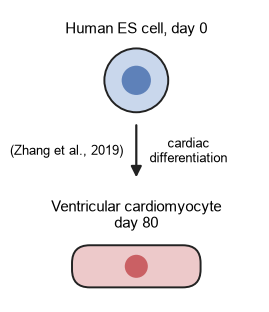

In [3]:
fig, ax = plt.subplots(figsize=(3.2, 3.8))
cx = 2.78                                              # horizontal centre (axis ranges keep circles round)
ax.set_xlim(0, 5.56)
ax.set_ylim(1.4, 8)
ax.set_aspect("equal")
ax.axis("off")

# hESC: label above, round cell + nucleus
ax.text(cx, 7.55, "Human ES cell, day 0", ha="center", va="center", fontsize=10.5)
ax.add_patch(Circle((cx, 6.4), 0.72, facecolor="#C9D7EC", edgecolor="#222222", lw=1.4))
ax.add_patch(Circle((cx, 6.4), 0.33, facecolor=PSC, edgecolor="none", alpha=0.85))

# differentiation arrow: citation on the left, process on the right
ax.add_patch(FancyArrowPatch((cx, 5.45), (cx, 4.15), arrowstyle="-|>", mutation_scale=16, lw=1.6, color="#222222"))
ax.text(cx - 0.3, 4.8, "(Zhang et al., 2019)", ha="right", va="center", fontsize=9)
ax.text(cx + 0.3, 4.8, "cardiac\ndifferentiation", ha="left", va="center", multialignment="center", fontsize=9.5)

# ventricular cardiomyocyte: label above, rod-shaped cell + nucleus
ax.text(cx, 3.35, "Ventricular cardiomyocyte\nday 80", ha="center", va="center", fontsize=10.5)
ax.add_patch(FancyBboxPatch((cx - 1.4, 1.78), 2.8, 0.85, boxstyle="round,pad=0.05,rounding_size=0.4",
                            facecolor="#EDC9CA", edgecolor="#222222", lw=1.4))
ax.add_patch(Circle((cx, 2.205), 0.26, facecolor=CM, edgecolor="none", alpha=0.85))

save(fig, "fig5a_schematic")
plt.show()

## Colocalization and expression of the cardiomyocyte gene sets
### Figure 5b — Colocalization and expression of the main cardiomyocyte gene sets
Left: fold enrichment of state-specific interchromosomal contacts (joint FDR). Right: GSEA NES, dot size = FDR.
Data: `data/panel_table.csv`.

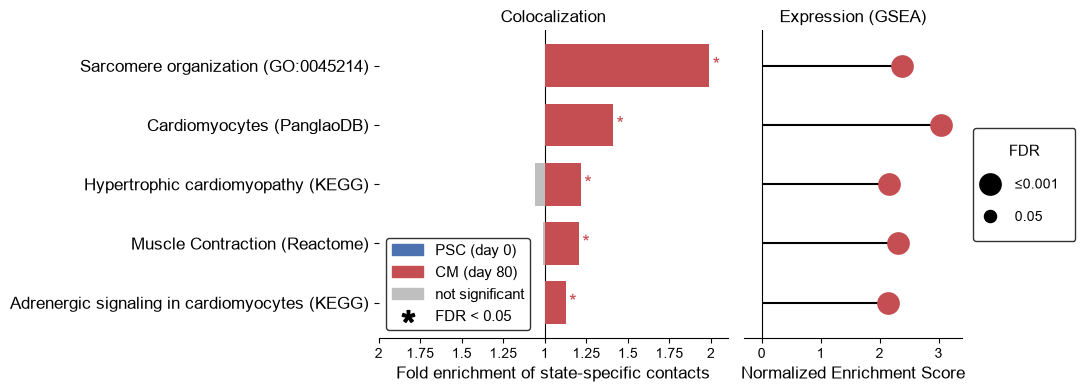

In [4]:
panel = pd.read_csv(f"{DATA}/panel_table.csv").sort_values("fold_day80").reset_index(drop=True)
y = np.arange(len(panel))
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 0.55 * len(panel) + 1.3), sharey=True,
                             gridspec_kw={"width_ratios": [1.6, 1]})

# colocalization: fold centred at 1, PSC left / CM right
for i, r in panel.iterrows():
    cm_sig = r.q_day80 < SIG_Q
    psc_sig = r.q_day00 < SIG_Q
    ax.barh(i, max(0, r.fold_day80 - 1), left=1, height=0.72, color=CM if cm_sig else GREY, zorder=3)
    ax.barh(i, -max(0, r.fold_day00 - 1), left=1, height=0.72, color=PSC if psc_sig else GREY, zorder=3)
    if cm_sig and r.fold_day80 > 1:
        ax.text(r.fold_day80 + 0.02, i, "*", va="center", color=CM, fontsize=14)
    if psc_sig and r.fold_day00 > 1:
        ax.text(2 - r.fold_day00 - 0.02, i, "*", va="center", ha="right", color=PSC, fontsize=14)

ax.axvline(1, color="k", lw=0.8)
ax.set(xticks=np.arange(0, 2.01, 0.25), xlim=(0, 2.1), yticks=y)
ax.set_xticklabels(["2", "1.75", "1.5", "1.25", "1", "1.25", "1.5", "1.75", "2"], fontsize=10)
ax.set_yticklabels(panel.gene_set, fontsize=12)
ax.set_xlabel("Fold enrichment of state-specific contacts", fontsize=12)
ax.set_title("Colocalization", fontsize=12)
coloc_legend = [Patch(color=PSC, label="PSC (day 0)"),
                Patch(color=CM, label="CM (day 80)"),
                Patch(color=GREY, label="not significant"),
                Line2D([], [], marker="$*$", color="k", linestyle="none", markersize=9, label="FDR < 0.05")]
ax.legend(handles=coloc_legend, loc="lower left", frameon=True, edgecolor="black", fontsize=11)   # empty PSC side

# expression: GSEA NES lollipop
bx.hlines(y=y, xmin=0, xmax=panel.nes, color="black", zorder=1)
for i, r in panel.iterrows():
    bx.plot(r.nes, i, "o", color=CM if r.nes >= 0 else PSC, markersize=p_size(max(r.nes_fdr, 0.001)), zorder=3)
bx.axvline(0, color="k", lw=0.8)
bx.set_xlim(-0.3, 3.4)
bx.tick_params(axis="x", labelsize=10)
bx.tick_params(axis="y", left=False)
bx.set_xlabel("Normalized Enrichment Score", fontsize=12)
bx.set_title("Expression (GSEA)", fontsize=12)
p_legend = [Line2D([], [], color="black", marker="o", linestyle="None", markersize=p_size(p), label=f"  {lab}")
            for p, lab in ((0.001, "≤0.001"), (0.05, "0.05"))]
bx.legend(handles=p_legend, title="FDR", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True, edgecolor="black",
          borderpad=1.2, labelspacing=1.4, handlelength=0, handletextpad=1.2, fontsize=10)

for a in (ax, bx):
    for sp in ("top", "right", "left"):
        a.spines[sp].set_visible(False)

plt.tight_layout()
save(fig, "fig5b_coloc_expression")
plt.show()

## Colocalization vs expression
x = GSEA NES, y = colocalization, log2(CM fold / PSC fold) (the ratio of the two fold enrichments in b; same metric and
orientation as Figure 4c). Data: `data/colocalization.csv` (pooled rows) with `data/supp_coloc_vs_expression_table.csv`
(5c) or `data/gsea_celltype.csv` (5d).

### Figure 5c — Colocalization versus expression, 60 pathways + 5 cardiomyocyte sets
Colour = per-state enrichment (hypergeometric, joint FDR < 0.05; as 5b and 5Sb a); filled = differentially expressed
(GSEA FDR < 0.05). The Fisher differential test is in `data/supp_table_pathways_perstate_and_fisher.csv` (not plotted).

In [5]:
pw = pathway_coloc[pathway_coloc.comparison == "pooled"].merge(pathways[["name", "expr_nes", "expr_fdr"]],
                                                               left_on="gene_set", right_on="name")
pw = pw.merge(pathways[["name", "fdr_day00", "fdr_day80"]], on="name")
pw["log2_ratio"] = np.log2(pw.fold_b / pw.fold_a)          # log2(CM fold / PSC fold)
# color = per-state enrichment (hypergeometric, joint FDR; same test as b and 5Sb a)
BOTH = "#7b3294"
cm_sig = pw.fdr_day80 < SIG_Q
psc_sig = pw.fdr_day00 < SIG_Q
pw["coloc_col"] = np.where(cm_sig & psc_sig, BOTH,                  # both
                           np.where(cm_sig, CM,                       # CM only
                                    np.where(psc_sig, PSC,            # PSC only
                                             "#9E9E9E")))             # neither
pw["de"] = pw.expr_fdr < SIG_Q

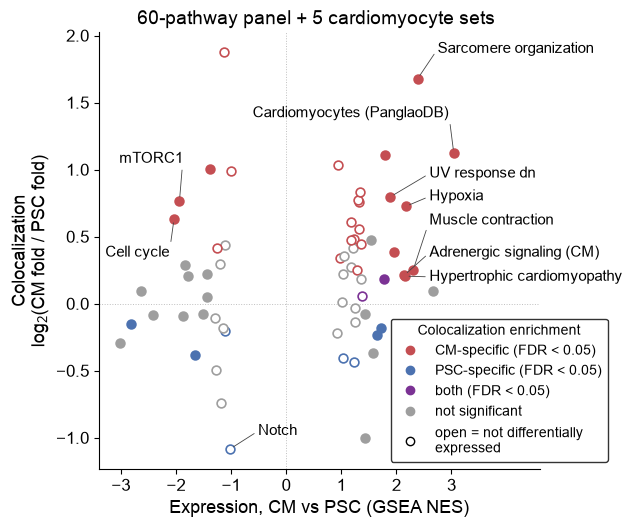

CM-enriched 26, PSC-enriched 8, both 2; CM-enriched and not DE: 15


In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
for _, r in pw.iterrows():
    fill = r.coloc_col if r.de else "white"                 # open circle = not differentially expressed
    ax.scatter(r.expr_nes, r.log2_ratio, s=40, color=fill, edgecolor=r.coloc_col, lw=1.2, zorder=3)

# labelled: the cardiac sets, Notch, and the CM-colocalized but repressed mTORC1 / cell cycle
# (label, label position in data coordinates, alignment)
PATHWAY_LABELS = {"Sarcomere organization (GO:0045214)": ("Sarcomere organization", (2.75, 1.9), "left"),
                  "Cardiomyocytes (PanglaoDB)": ("Cardiomyocytes (PanglaoDB)", (2.95, 1.42), "right"),
                  "Muscle Contraction (Reactome)": ("Muscle contraction", (2.6, 0.62), "left"),
                  "Adrenergic signaling in cardiomyocytes (KEGG)": ("Adrenergic signaling (CM)", (2.6, 0.38), "left"),
                  "Hypertrophic cardiomyopathy (KEGG)": ("Hypertrophic cardiomyopathy", (2.6, 0.2), "left"),
                  "Notch signaling (H)": ("Notch", (0.2, -0.95), "right"),
                  "MTORC1 signaling (H)": ("mTORC1", (-2.45, 1.08), "center"),
                  "Cell cycle (KEGG)": ("Cell cycle", (-2.7, 0.38), "center"),
                  "Uv response dn (H)": ("UV response dn", (2.6, 0.97), "left"),
                  "Hypoxia (H)": ("Hypoxia", (2.6, 0.8), "left")}
for _, r in pw[pw.gene_set.isin(PATHWAY_LABELS)].iterrows():
    text, xy_text, ha = PATHWAY_LABELS[r.gene_set]
    side = 1 if r.expr_nes > xy_text[0] else 0              # leader leaves from the label end facing the point
    ax.annotate(text, (r.expr_nes, r.log2_ratio), xytext=xy_text, textcoords="data", fontsize=10.5, ha=ha, va="center",
                arrowprops=dict(arrowstyle="-", color="#444444", lw=0.6, shrinkA=1, shrinkB=3, relpos=(side, 0.5)),
                zorder=5)
ax.axhline(0, color="0.75", lw=0.7, ls=":")
ax.axvline(0, color="0.75", lw=0.7, ls=":")
ax.set_xlim(-3.4, 4.6)
ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
title = ax.set_title("60-pathway panel + 5 cardiomyocyte sets", fontsize=14)
ax.set_xlabel("Expression, CM vs PSC (GSEA NES)", fontsize=13)
ax.tick_params(labelsize=12)
ax.set_ylabel("Colocalization\nlog$_2$(CM fold / PSC fold)", fontsize=13)
pw_legend = [Line2D([], [], marker="o", ls="none", color=CM, label="CM-specific (FDR < 0.05)"),
             Line2D([], [], marker="o", ls="none", color=PSC, label="PSC-specific (FDR < 0.05)"),
             Line2D([], [], marker="o", ls="none", color=BOTH, label="both (FDR < 0.05)"),
             Line2D([], [], marker="o", ls="none", color="#9E9E9E", label="not significant"),
             Line2D([], [], marker="o", ls="none", markerfacecolor="white", markeredgecolor="k",
                    label="open = not differentially\nexpressed")]
ax.legend(handles=pw_legend, loc="lower right", bbox_to_anchor=(1.17, 0.0), fontsize=10, frameon=True,
          edgecolor="black", title="Colocalization enrichment", title_fontsize=10)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
# center the title over the whole panel (y label to legend edge), not over the axes
fig.canvas.draw()
panel_box = fig.get_tightbbox(fig.canvas.get_renderer())
title.set_x(ax.transAxes.inverted().transform(((panel_box.x0 + panel_box.x1) / 2 * fig.dpi, 0))[0])
save(fig, "fig5c_coloc_vs_expression")
plt.show()
print(f"CM-enriched {int((cm_sig & ~psc_sig).sum())}, PSC-enriched {int((psc_sig & ~cm_sig).sum())}, "
      f"both {int((cm_sig & psc_sig).sum())}; CM-enriched and not DE: {int((cm_sig & ~pw.de).sum())}")

### Figure 5d — Cell-type specificity, 178 PanglaoDB cell types

In [7]:
celltypes = coloc.query("category == 'celltype' and comparison == 'pooled'")
celltype_gsea = pd.read_csv(f"{DATA}/gsea_celltype.csv").rename(columns={"Term": "gene_set"})
celltypes = celltypes.merge(celltype_gsea[["gene_set", "NES"]], on="gene_set")
celltypes["log2_ratio"] = np.log2(celltypes.fold_b / celltypes.fold_a)     # log2(CM fold / PSC fold)

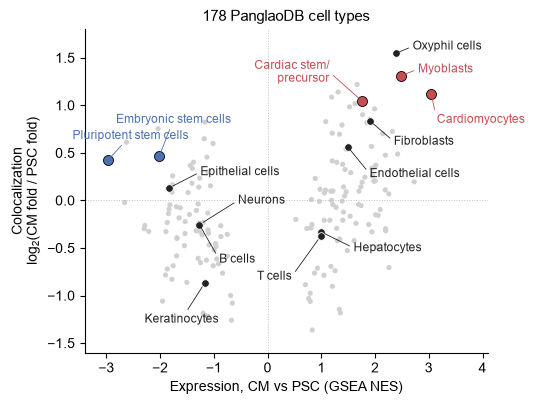

In [8]:
INK = "#222222"
CELL_GROUPS = [  # (cell types, color, marker size)
    (["Cardiomyocytes", "Cardiac Stem And Precursor Cells", "Myoblasts"], CM, 52),
    (["Embryonic Stem Cells", "Pluripotent Stem Cells"], PSC, 52),
    (["Hepatocytes", "Neurons", "T Cells", "B Cells", "Oxyphil Cells",
      "Epithelial Cells", "Keratinocytes", "Fibroblasts", "Endothelial Cells"], INK, 30),
]
# label text, label position (data coordinates: NES, log2 ratio), horizontal alignment
CELL_LABELS = {
    "Cardiomyocytes": ("Cardiomyocytes", (3.15, 0.85), "left"),
    "Myoblasts": ("Myoblasts", (2.8, 1.38), "left"),
    "Oxyphil Cells": ("Oxyphil cells", (2.7, 1.62), "left"),
    "Cardiac Stem And Precursor Cells": ("Cardiac stem/\nprecursor", (1.15, 1.35), "right"),
    "Fibroblasts": ("Fibroblasts", (2.35, 0.62), "left"),
    "Endothelial Cells": ("Endothelial cells", (1.9, 0.28), "left"),
    "Hepatocytes": ("Hepatocytes", (1.6, -0.5), "left"),
    "Neurons": ("Neurons", (-0.55, 0.0), "left"),
    "T Cells": ("T cells", (0.45, -0.8), "right"),
    "B Cells": ("B cells", (-0.9, -0.62), "left"),
    "Keratinocytes": ("Keratinocytes", (-1.6, -1.25), "center"),
    "Epithelial Cells": ("Epithelial cells", (-1.25, 0.3), "left"),
    "Embryonic Stem Cells": ("Embryonic stem cells", (-1.75, 0.85), "center"),
    "Pluripotent Stem Cells": ("Pluripotent stem cells", (-2.55, 0.68), "center"),
}
highlighted = [n for names, _, _ in CELL_GROUPS for n in names]

fig, ax = plt.subplots(figsize=(5.2, 4.2))
other = celltypes[~celltypes.gene_set.isin(highlighted)]
ax.scatter(other.NES, other.log2_ratio, s=14, color="#D0D0D0", edgecolor="none", zorder=2)
for names, col, size in CELL_GROUPS:
    sub = celltypes[celltypes.gene_set.isin(names)]
    ax.scatter(sub.NES, sub.log2_ratio, s=size, color=col, edgecolor="white" if col == INK else "black", lw=0.6, zorder=4)
for _, r in celltypes[celltypes.gene_set.isin(highlighted)].iterrows():
    text, xy_text, ha = CELL_LABELS[r.gene_set]
    col = next(c for names, c, _ in CELL_GROUPS if r.gene_set in names)
    side = 0.5 if ha == "center" else (1 if r.NES > xy_text[0] else 0)     # leader leaves the label end facing the point
    ax.annotate(text, (r.NES, r.log2_ratio), xytext=xy_text, textcoords="data", fontsize=8.5, color=col, ha=ha, va="center",
                arrowprops=dict(arrowstyle="-", color=col, lw=0.6, shrinkA=1, shrinkB=3, relpos=(side, 0.5)), zorder=5)

ax.axhline(0, color="0.75", lw=0.7, ls=":")
ax.axvline(0, color="0.75", lw=0.7, ls=":")
ax.set_xlim(-3.4, 4.1)
ax.set_ylim(-1.6, 1.8)
ax.set_xlabel("Expression, CM vs PSC (GSEA NES)", fontsize=10)
ax.set_ylabel("Colocalization\nlog$_2$(CM fold / PSC fold)", fontsize=10)
ax.set_title("178 PanglaoDB cell types", fontsize=11)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
save(fig, "fig5d_celltype_specificity")
plt.show()

## CM-specific core clusters
Densest k-core of the CM-only colocalization graph (`data/kcores/`); gene pairs coloured by contact state, strips mark
each gene's chromosome (paper-wide palette, shared `../kcore.py`).

In [9]:
print(pd.read_csv(f"{DATA}/kcores/kcore_summary.csv").to_string(index=False))

         core                            gene_set  k  n_genes  n_chromosomes  pairs_day80  pairs_day00  pairs_Shared
    sarcomere Sarcomere organization (GO:0045214)  5       10              7           29            0             7
cardiomyocyte          Cardiomyocytes (PanglaoDB) 17       43             19          474            8           200


In [10]:
cmap = ListedColormap(["#F2F2F2", CM, PSC, "#B0B0B0"])    # none (incl. same-bin pairs) | CM-only | PSC-only | shared
state_legend = [Patch(color=CM, label="CM-only"),
                Patch(color=PSC, label="PSC-only"),
                Patch(color="#B0B0B0", label="Shared")]

In [11]:
def plot_module(core, short, figsize, fs, name, legend_fs):
    """One module heatmap (with chromosome strips) and the contact-state legend underneath, centred on the heatmap."""
    genes = pd.read_csv(f"{DATA}/kcores/{core}_genes.csv")
    mat = pd.read_csv(f"{DATA}/kcores/{core}_states.csv", index_col=0).to_numpy()
    fig, ax = plt.subplots(figsize=figsize)
    ax.matshow(mat, cmap=cmap, vmin=-0.5, vmax=3.5, aspect="equal")   # square cells
    kcore.chrom_strips(ax, genes.gene.tolist(), genes.chrom.tolist(), fs, strip_size=0.28)
    ax.set_title(f"{short} core cluster", fontsize=14)
    plt.tight_layout()
    # x in heatmap-axis units (centred under the heatmap, not the gene labels), y in figure units (below the figure)
    centred_below = blended_transform_factory(ax.transAxes, fig.transFigure)
    fig.legend(handles=state_legend, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.0), bbox_transform=centred_below,
               frameon=True, edgecolor="black", fontsize=legend_fs)
    save(fig, name)
    plt.show()

### Figure 5e — Sarcomere organization (GO), CM-specific core cluster
5e and 5f are placed at the same height on the page, so 5e's legend font is scaled by 6.0 / 7.6 (the figure sizes) to print
at the same size as 5f's.

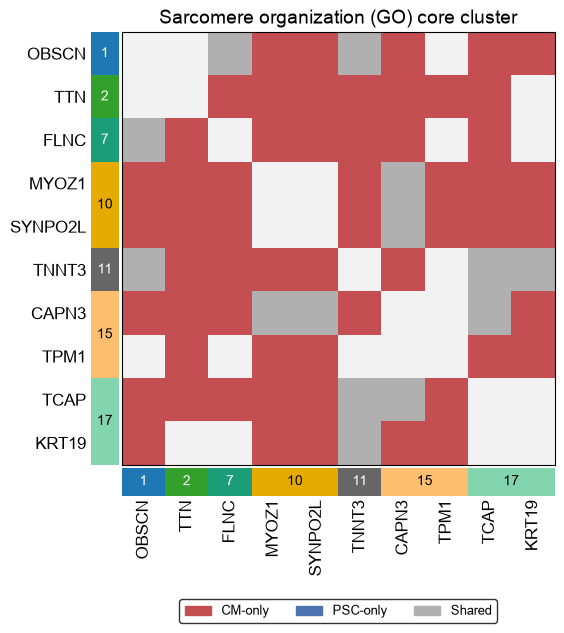

In [12]:
plot_module("sarcomere", "Sarcomere organization (GO)", (6.0, 6.0), 12, "fig5e_sarcomere_core_cluster",
            legend_fs=12 * 6.0 / 7.6)

### Figure 5f — Cardiomyocytes (PanglaoDB), CM-specific core cluster

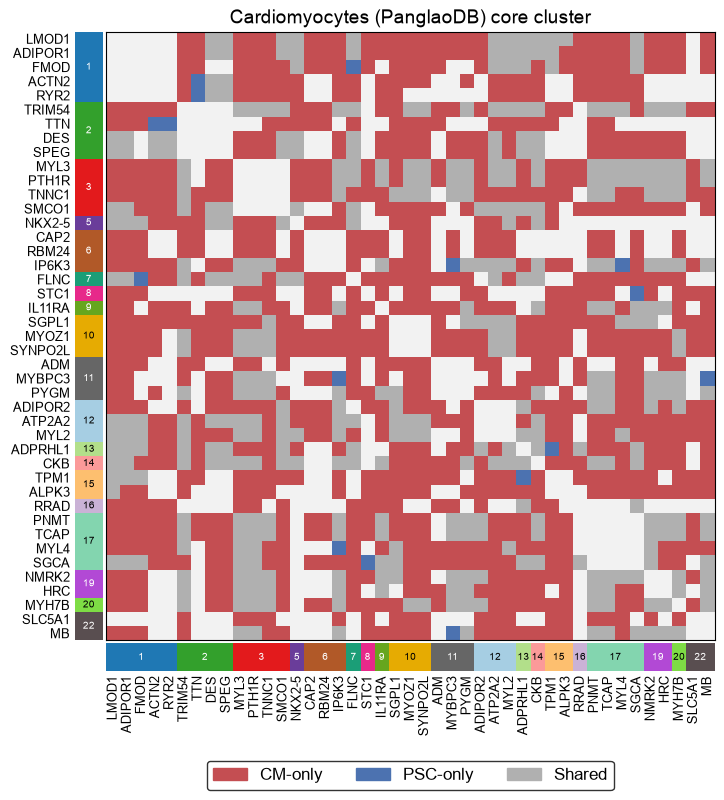

In [13]:
plot_module("cardiomyocyte", "Cardiomyocytes (PanglaoDB)", (7.6, 7.6), 9, "fig5f_cardiomyocyte_core_cluster", legend_fs=12)

## Robustness: replicates and all published gene sets

### Supplementary Figure 5Sa, panel a — Replicate design
Two biological replicates per state; *pooled* merges both, and each PSC replicate is paired with each CM replicate (4
replicate pairs).

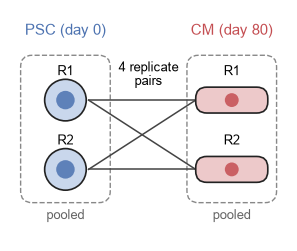

In [14]:
fig, ax = plt.subplots(figsize=(3.6, 3.0))
ax.set_xlim(0, 6)
ax.set_ylim(0, 5)
ax.set_aspect("equal")
ax.axis("off")

psc_x = 1.2
cm_x = 4.8
rep_y = {"R1": 3.05, "R2": 1.55}
ax.text(psc_x, 4.55, "PSC (day 0)", ha="center", va="center", fontsize=10.5, color=PSC)
ax.text(cm_x, 4.55, "CM (day 80)", ha="center", va="center", fontsize=10.5, color=CM)

# dashed "pooled" box around both replicates of each state
for x in (psc_x, cm_x):
    ax.add_patch(FancyBboxPatch((x - 0.95, 0.85), 1.9, 3.15, boxstyle="round,pad=0.02,rounding_size=0.25",
                                facecolor="none", edgecolor="#888888", lw=1.0, ls="--"))
    ax.text(x, 0.55, "pooled", ha="center", va="center", fontsize=9, color="#666666")   # pooled = R1 + R2 merged

# the 4 cross-state replicate pairs (each PSC replicate with each CM replicate)
for y0 in rep_y.values():
    for y1 in rep_y.values():
        ax.plot([psc_x + 0.5, cm_x - 0.78], [y0, y1], color="#444444", lw=1.1, zorder=1)
ax.text(3.0, 3.6, "4 replicate\npairs", ha="center", va="center", fontsize=9.5, linespacing=1.1)

# replicate cells: round hESC (as 5a) and rod-shaped cardiomyocyte (as 5a)
for rep, y in rep_y.items():
    ax.add_patch(Circle((psc_x, y), 0.45, facecolor="#C9D7EC", edgecolor="#222222", lw=1.2, zorder=2))
    ax.add_patch(Circle((psc_x, y), 0.2, facecolor=PSC, edgecolor="none", alpha=0.85, zorder=2))
    ax.add_patch(FancyBboxPatch((cm_x - 0.75, y - 0.25), 1.5, 0.5, boxstyle="round,pad=0.03,rounding_size=0.24",
                                facecolor="#EDC9CA", edgecolor="#222222", lw=1.2, zorder=2))
    ax.add_patch(Circle((cm_x, y), 0.15, facecolor=CM, edgecolor="none", alpha=0.85, zorder=2))
    ax.text(psc_x, y + 0.62, rep, ha="center", va="center", fontsize=9)
    ax.text(cm_x, y + 0.62, rep, ha="center", va="center", fontsize=9)

save(fig, "fig5Sa_a_replicate_design")
plt.show()

### Supplementary Figure 5Sa, panel b — Cardiomyocyte gene sets in each replicate pair
Pooled CM-specific fold (bar) and each cross-state replicate pair (dots; filled p < 0.05). Data: `data/colocalization.csv`;
the Spearman agreement with the pooled profile (figure-legend text) is in `data/replicate_agreement.csv`.

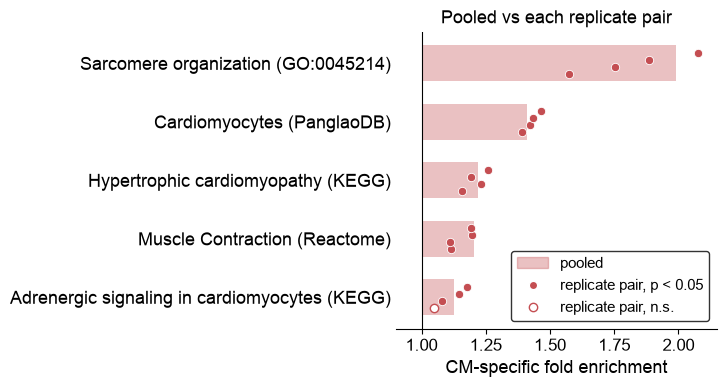

In [15]:
cm_sets = pathway_coloc[pathway_coloc.category == "cardiomyocyte"]

fig, ax = plt.subplots(figsize=(7.4, 4.0))
order = cm_sets[cm_sets.comparison == "pooled"].sort_values("fold_b").gene_set.tolist()
for i, gene_set in enumerate(order):
    rows = cm_sets[cm_sets.gene_set == gene_set]
    pooled = rows[rows.comparison == "pooled"].fold_b.iloc[0]
    pairs = rows[rows.kind == "cross"]                       # the 4 cross-state replicate pairs
    sig = (pairs.p_b < 0.05).values
    ax.barh(i, pooled - 1, left=1, height=0.62, color=CM, alpha=0.35, zorder=2)
    y = i + np.linspace(-0.18, 0.18, len(pairs))
    # filled = replicate pair p < 0.05, open = not significant
    ax.scatter(pairs.fold_b.values[sig], y[sig], s=36, color=CM, edgecolor="white", lw=0.6, zorder=3)
    ax.scatter(pairs.fold_b.values[~sig], y[~sig], s=36, facecolor="white", edgecolor=CM, lw=1.0, zorder=3)
ax.axvline(1, color="k", lw=0.8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=13)
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0.9, 2.15)
ax.set_xlabel("CM-specific fold enrichment", fontsize=13)
ax.set_title("Pooled vs each replicate pair", fontsize=13)
rep_legend = [plt.Rectangle((0, 0), 1, 1, color=CM, alpha=0.35, label="pooled"),
              Line2D([], [], marker="o", ls="none", color=CM, markeredgecolor="white",
                     label="replicate pair, p < 0.05"),
              Line2D([], [], marker="o", ls="none", markerfacecolor="white", markeredgecolor=CM,
                     label="replicate pair, n.s.")]
ax.legend(handles=rep_legend, loc="lower right", fontsize=11, frameon=True, edgecolor="black")
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
save(fig, "fig5Sa_b_replicate_sets")
plt.show()

#### Shared layout for Supplementary Figure 5Sa, panels c, d
Same layout as Figure 5b; grey = not significant (colocalization: joint FDR; expression: GSEA FDR); [n] =
interchromosomal gene–gene contacts in the set. Data: `data/supp_cardiac_sets_table.csv`, `data/supp_stemness_sets_table.csv`.

In [16]:
def sets_panel(table, name, row_h=0.40, label_fs=14, show_n=True):
    """Colocalization (diverging fold, PSC left / CM right) + GSEA NES lollipop for every set in a table."""
    t = table.sort_values("fold_day80").reset_index(drop=True)
    y = np.arange(len(t))
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(13.5, row_h * len(t) + 1.6), sharey=True,
                                 gridspec_kw={"width_ratios": [1.6, 1]})
    for i, r in t.iterrows():
        cm_sig = r.q_day80 < SIG_Q
        psc_sig = r.q_day00 < SIG_Q
        ax.barh(i, max(0, r.fold_day80 - 1), left=1, height=0.72, color=CM if cm_sig else GREY, zorder=3)
        ax.barh(i, -max(0, r.fold_day00 - 1), left=1, height=0.72, color=PSC if psc_sig else GREY, zorder=3)
        if cm_sig and r.fold_day80 > 1:
            ax.text(r.fold_day80 + 0.02, i, "*", va="center", color=CM, fontsize=16 if row_h > 0.3 else 10)
        if psc_sig and r.fold_day00 > 1:
            ax.text(2 - r.fold_day00 - 0.02, i, "*", va="center", ha="right", color=PSC, fontsize=16 if row_h > 0.3 else 10)
    ax.axvline(1, color="k", lw=0.8)
    ax.set(xticks=np.arange(0, 2.01, 0.5), xlim=(-0.05, 2.1), yticks=y)
    ax.set_xticklabels(["2", "1.5", "1", "1.5", "2"], fontsize=12)
    labels = [f"{g}  [{int(n)}]" for g, n in zip(t.gene_set, t.N)] if show_n else list(t.gene_set)
    ax.set_yticklabels(labels, fontsize=label_fs)
    ax.set_xlabel("Fold enrichment of\nstate-specific contacts", fontsize=14)
    ax.set_title("Colocalization", fontsize=14)
    coloc_legend = [Patch(color=PSC, label="PSC (day 0)"),
                    Patch(color=CM, label="CM (day 80)"),
                    Patch(color=GREY, label="not significant"),
                    Line2D([], [], marker="$*$", color="k", linestyle="none", markersize=9, label="FDR < 0.05")]

    nes_sig = t["FDR q-val"] < SIG_Q
    colors = [GREY if not s else (CM if v > 0 else PSC) for v, s in zip(t.NES, nes_sig)]
    bx.hlines(y=y, xmin=0, xmax=t.NES, color="black", zorder=1)
    # size = GSEA FDR, between 0.001 (q = 0 with 1000 permutations) and 0.05 (n.s. sets drawn at the 0.05 size)
    bx.scatter(t.NES, y, s=[p_size(min(max(q, 0.001), 0.05)) ** 2 for q in t["FDR q-val"]], c=colors, zorder=3)
    bx.axvline(0, color="k", lw=0.8)
    bx.set_xlim(-3.6, 3.6)
    bx.set_xticks([-2, 0, 2])
    bx.tick_params(axis="x", labelsize=12)
    bx.tick_params(axis="y", left=False)
    bx.set_xlabel("Normalized\nEnrichment Score", fontsize=14)
    bx.set_title("Expression (GSEA)", fontsize=14)
    fdr_legend = [Line2D([], [], color="black", marker="o", linestyle="None", markersize=p_size(q), label=f"  {lab}")
                  for q, lab in ((0.001, "≤0.001"), (0.05, "0.05"))]
    fdr_legend.append(Line2D([], [], color=GREY, marker="o", linestyle="None", markersize=p_size(0.05), label="  n.s."))
    # legends in a column right of the GSEA panel: GSEA FDR (dot size) above, colocalization (bars) below
    fdr_leg = bx.legend(handles=fdr_legend, title="GSEA FDR", loc="lower left", bbox_to_anchor=(1.04, 0.52),
                        frameon=True, edgecolor="black", borderpad=1.0, labelspacing=1.2, handlelength=0, handletextpad=1.2, fontsize=12, title_fontsize=12)
    bx.add_artist(fdr_leg)
    bx.legend(handles=coloc_legend, title="Colocalization", loc="upper left", bbox_to_anchor=(1.04, 0.46),
              frameon=True, edgecolor="black", fontsize=12, title_fontsize=12)
    for a in (ax, bx):
        for sp in ("top", "right", "left"):
            a.spines[sp].set_visible(False)
    plt.tight_layout()
    save(fig, name)
    plt.show()

### Supplementary Figure 5Sa, panel c — All published cardiomyocyte gene sets

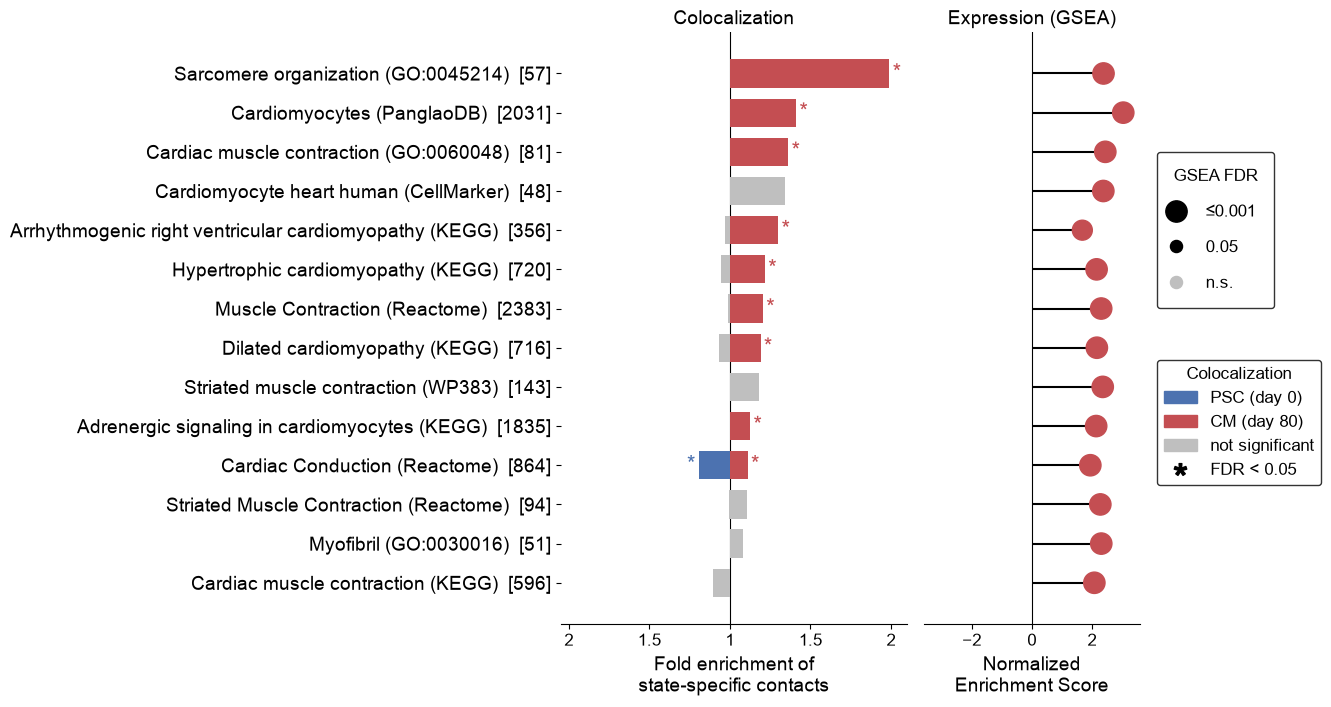

In [17]:
sets_panel(pd.read_csv(f"{DATA}/supp_cardiac_sets_table.csv"), "fig5Sa_c_all_cardiac_sets")

### Supplementary Figure 5Sa, panel d — All published stemness / pluripotency gene sets

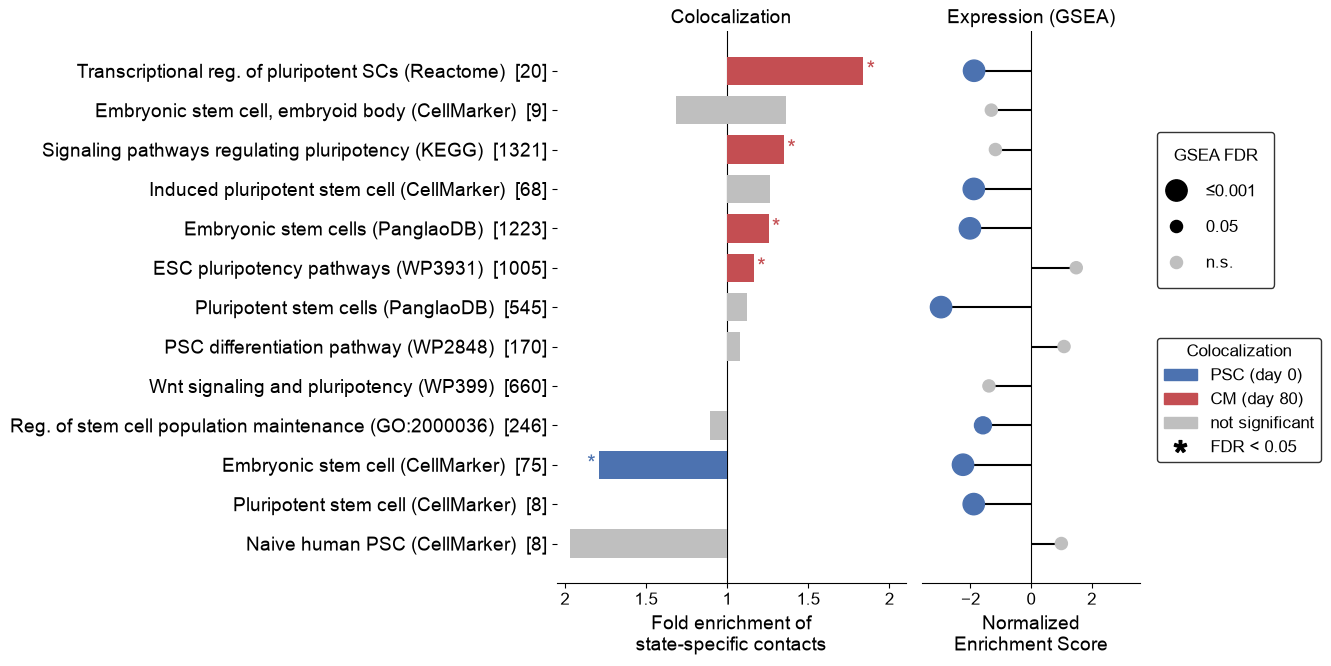

In [18]:
sets_panel(pd.read_csv(f"{DATA}/supp_stemness_sets_table.csv"), "fig5Sa_d_all_stemness_sets")

## Pathway context: 60-pathway panel
The 60-pathway panel (Hallmark + custom): a, pathways significantly colocalized in CM or PSC (joint FDR < 0.05); b,
differentially expressed pathways (GSEA FDR < 0.05). Figure 5c compares the two. Data:
`data/supp_coloc_vs_expression_table.csv`.

In [19]:
hallmark_names = set(json.load(open(HALLMARK_JSON)))
hall = pathways[pathways.name.isin(hallmark_names)].copy()
hall["label"] = hall.name.str.replace(" (H)", "", regex=False)
hall["cm_sig"] = (hall.fdr_day80 < SIG_Q) & (hall.fold_day80 > 1)
hall["psc_sig"] = (hall.fdr_day00 < SIG_Q) & (hall.fold_day00 > 1)
coloc_rows = pd.concat([hall[hall.psc_sig & ~hall.cm_sig].sort_values("fold_day00", ascending=False),
                        hall[hall.cm_sig].sort_values("fold_day80")]).reset_index(drop=True)
de_rows = hall[hall.expr_fdr < SIG_Q].sort_values("expr_nes").reset_index(drop=True)
print(f"{len(hall)} pathways: {int(hall.cm_sig.sum())} CM-colocalized, {int(hall.psc_sig.sum())} PSC-colocalized "
      f"({int((hall.cm_sig & hall.psc_sig).sum())} both); {len(de_rows)} differentially expressed")

60 pathways: 23 CM-colocalized, 10 PSC-colocalized (2 both); 26 differentially expressed


### Supplementary Figure 5Sb, panel a — Colocalized pathways

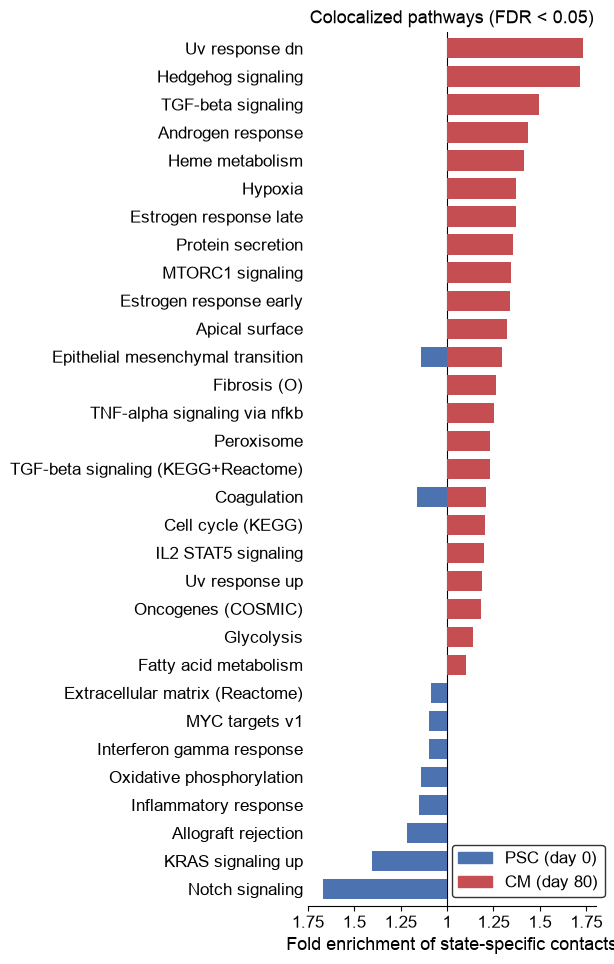

In [20]:
fig, ax = plt.subplots(figsize=(6.4, 0.27 * len(coloc_rows) + 1.4))
for i, r in coloc_rows.iterrows():
    if r.cm_sig:
        ax.barh(i, r.fold_day80 - 1, left=1, height=0.72, color=CM, zorder=3)
    if r.psc_sig:
        ax.barh(i, -(r.fold_day00 - 1), left=1, height=0.72, color=PSC, zorder=3)
ax.axvline(1, color="k", lw=0.8)
ax.set(xticks=np.arange(0.25, 1.76, 0.25), xlim=(0.25, 1.8), yticks=range(len(coloc_rows)))
ax.set_xticklabels(["1.75", "1.5", "1.25", "1", "1.25", "1.5", "1.75"], fontsize=12)
ax.set_yticklabels(coloc_rows.label, fontsize=12)
ax.set_ylim(-0.6, len(coloc_rows) - 0.4)
ax.set_xlabel("Fold enrichment of state-specific contacts", fontsize=13)
ax.set_title("Colocalized pathways (FDR < 0.05)", fontsize=13)
ax.legend(handles=[Patch(color=PSC, label="PSC (day 0)"), Patch(color=CM, label="CM (day 80)")],
          loc="lower right", bbox_to_anchor=(1.06, 0), frameon=True, edgecolor="black", fontsize=12)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
save(fig, "fig5Sb_a_pathway_colocalization")
plt.show()

### Supplementary Figure 5Sb, panel b — Differentially expressed pathways

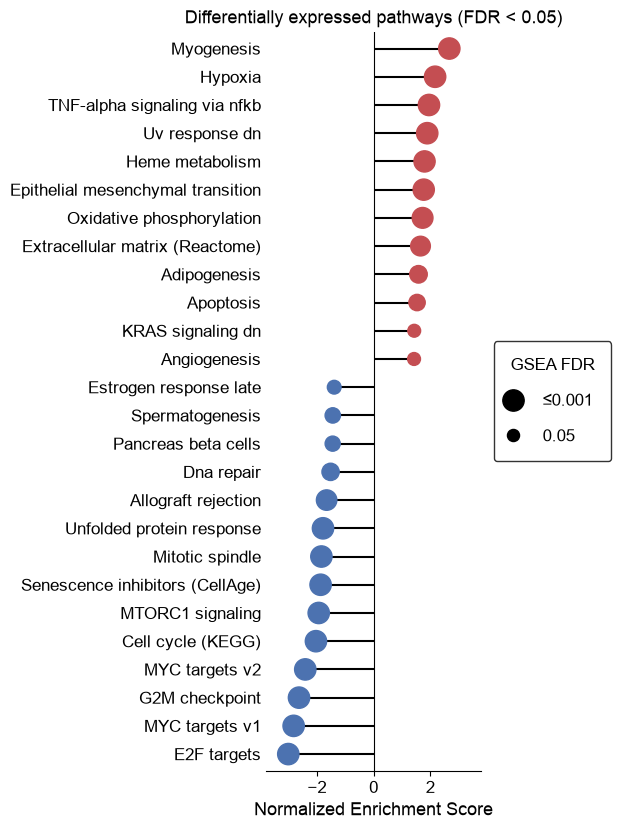

In [21]:
fig, ax = plt.subplots(figsize=(6.4, 0.27 * len(de_rows) + 1.4))
y = np.arange(len(de_rows))
ax.hlines(y=y, xmin=0, xmax=de_rows.expr_nes, color="black", zorder=1)
# size = GSEA FDR (q = 0 means < 0.001 with 1000 permutations)
ax.scatter(de_rows.expr_nes, y, s=[p_size(max(q, 0.001)) ** 2 for q in de_rows.expr_fdr],
           c=[CM if v > 0 else PSC for v in de_rows.expr_nes], zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(de_rows.label, fontsize=12)
ax.set_ylim(-0.6, len(de_rows) - 0.4)
ax.set_xlim(-3.8, 3.8)
ax.set_xticks([-2, 0, 2])
ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Normalized Enrichment Score", fontsize=13)
ax.set_title("Differentially expressed pathways (FDR < 0.05)", fontsize=13)
fdr_legend = [Line2D([], [], color="black", marker="o", linestyle="None", markersize=p_size(q), label=f"  {lab}")
              for q, lab in ((0.001, "≤0.001"), (0.05, "0.05"))]
ax.legend(handles=fdr_legend, title="GSEA FDR", loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True,
          edgecolor="black", borderpad=1.0, labelspacing=1.2, handlelength=0, handletextpad=1.2, fontsize=12,
          title_fontsize=12)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
plt.tight_layout()
save(fig, "fig5Sb_b_pathway_expression")
plt.show()